# Lab 5 Practical assignment - End-to-End Predictive Maintenance Pipeline

**Duration:** 4 hours (in class) · **Teams:** 2–3 students · **Deliverable:** this notebook, completed, run top-to-bottom, with the short report in Part 7

In this lab, you will build a predictive-maintenance pipeline for turbofan engines, from raw sensor data to a trained machine-learning model that predicts the Remaining Useful Life (RUL) of each engine. You will also have the opportunity to extend this pipeline with a streaming job that generates alerts when new sensor readings arrive (optional Part 5).

You will reuse concepts and techniques from previous labs: Spark DataFrames and SparkSQL, the RDD API, query plans and optimization (Lab 2), and Structured Streaming (Lab 3). You will also apply Spark MLlib to train and evaluate regression models.

The selected model will serve as a classical machine-learning baseline for the distributed deep-learning model you will develop in Lab 6. In Part 6, you will prepare and export the sensor data and baseline results needed for that next lab.

Through this assignment, you will:
- Build a data processing pipeline: ingest raw sensor data, convert it into typed Parquet datasets, validate and clean the data, and organize the processing stages using the Bronze, Silver, and Gold data-layer approach.
- Apply distributed data processing: use Spark DataFrames, Spark SQL, and window functions to explore sensor measurements, construct RUL labels, and engineer temporal features.
- Develop a machine-learning workflow: use Spark MLlib to build regression pipelines, train and compare models, and evaluate their predictive performance.
- Understand production-oriented processing: explore how the pipeline can be extended to process incoming sensor data and generate predictive-maintenance alerts through Structured Streaming (optional Part 5).
- Prepare for distributed deep learning: export the processed data and baseline evaluation results for use in Lab 6, where you will develop a distributed deep-learning model.

**Team members** 

| Member 1 | Member 2 | Member 3 (optional) |
|---|---|---|
|  | | |

## Conventions used in this notebook

- `TODO x.y` : code you must write. Replace every `...`. Do not change function names or signatures: later parts call them.
- ✅ **Check cells** : run them after each TODO. If a check fails, fix your code before moving on.
- 🛟 **Fallback cells** : see below. Only use them if you are stuck.
- ⭐ **Optional** : bonus work for fast teams. Skip it if you are behind schedule.
- ❓ **Questions** : answer them briefly in the report (Part 7), not in the middle of the code.

### 🛟 Fallback checkpoints

Each part starts from the output of the previous one. If your team is stuck and running out of time, do not lose the rest of the lab: ask the instructor for the fallback pack, unzip it as `fallback/` next to this notebook, and restart from the next checkpoint.

| Checkpoint | Folder | Contains | Use it to start… |
|---|---|---|---|
| **CP0** | `data/CMAPSSData/` | raw NASA files (`train/test/RUL_FD001.txt`) | Part 1, if the download fails |
| **CP1** | `fallback/cp1_bronze/` | Bronze tables `train`, `test`, `rul_truth` | Part 2 |
| **CP2** | `fallback/cp2_silver/` | Silver tables + selected sensors | Part 3 |
| **CP3** | `fallback/cp3_gold/` | Gold feature tables + feature list | Part 4 (or 6) |
| **CP4** | `fallback/cp4_model/` | trained baseline `PipelineModel` | Part 5 |

How to use it: at the top of the part you want to start from, set `USE_FALLBACK = True` in the 🛟 cell and run it. It reloads **all** checkpoints up to that point (and reference versions of the functions later parts need), so the following cells work.
Using a fallback costs the points of the part you skipped only — you can still earn everything after it. Say in your report which fallbacks you used.

**Grading (100 pts)**

| Part 1 | Part 2 | Part 3 | Part 4 | Part 5 | Part 6 | Report | Reproducibility* |
|---|---|---|---|---|---|---|---|
| 10 | 15 | 20 | 25 | 10 | 5 | 10 | 5 |


### Context — the C-MAPSS dataset

NASA's **C-MAPSS** (Commercial Modular Aero-Propulsion System Simulation) dataset simulates fleets of turbofan engines. Every engine starts healthy with some unknown initial wear, then a fault appears and grows until the engine fails.

- **`train_FD001.txt`** — 100 engines recorded until failure (run-to-failure).
- **`test_FD001.txt`** — 100 other engines, recordings stopped some time before failure.
- **`RUL_FD001.txt`** — the true remaining life of each test engine at its last recorded cycle (line *i* ↔ engine *i*).

Each line = one engine × one cycle (≈ one flight): `unit_id, cycle, 3 operational settings, 21 sensors`, separated by spaces.
FD001 is the simplest subset (one operating condition, one fault mode). FD002–FD004 add operating conditions and fault modes (⭐ bonus).

**Target.** For a training engine, at cycle *t*: `RUL = last_cycle − t`. Early in life the engine shows no degradation, so the true RUL is not predictable from sensors; the standard practice is to cap the label: `rul_capped = min(RUL, 125)` (*piece-wise linear* target).

```
 raw .txt ─► P1 BRONZE ─► P2 SILVER ─────► P3 GOLD ─────► P4 MLlib model ─► P5 streaming scoring + alerts
             typed         cleaned +         rolling          baseline           (foreachBatch)
             parquet       RUL labels        window feats
                              │                                   │
                              └────────► P6 dl_ready/ + baseline_metrics.json ───────► Lab 6 (distributed DL)
```

---
## Part 0 — Setup

Requirements (same environment as the previous labs): Java 17+, `pyspark >= 3.4` (tested with 4.2), `pandas`, `pyarrow`, `matplotlib`. Keep the Spark UI (http://localhost:4040) open in a browser tab ; you will need it.

In [8]:
import os, json, time, shutil, importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, DataFrame, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T

spark = (SparkSession.builder
         .appName("Lab5-PredictiveMaintenance")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")      # small data: 200 partitions would be wasteful (Lab 2)
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.driver.memory", "4g")
         .config("spark.ui.showConsoleProgress", "false")  # no progress bars in the notebook (Spark UI: http://localhost:4040)
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Spark 4.2.0 | cores: 12


In [9]:
# ── Configuration ───────────────────────────────────────────────────────────
TEAM = {"name": "team-rocket", "amine bouaouda": ["zakaria bettar"]}   # ← edit

SUBSET = "FD001"           # keep FD001 for the graded part
RUL_CAP = 125              # piece-wise linear target
WINDOW_SIZE = 10           # cycles used for rolling features
ALERT_THRESHOLD = 30       # alert when predicted RUL < 30 cycles
SEED = 42

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data" / "CMAPSSData"
OUT_DIR = BASE_DIR / "lab5_outputs"
FALLBACK_DIR = BASE_DIR / "fallback"
P = {name: OUT_DIR / name for name in ["bronze", "silver", "gold", "models", "stream", "dl_ready"]}
OUT_DIR.mkdir(exist_ok=True)

SETTING_COLS = [f"setting_{i}" for i in range(1, 4)]
SENSOR_COLS = [f"s{i}" for i in range(1, 22)]
RAW_COLS = ["unit_id", "cycle"] + SETTING_COLS + SENSOR_COLS
print(len(RAW_COLS), "raw columns")

26 raw columns


In [10]:
# ── Helpers (provided) ─────────────────────────────────────────────────────
def check(condition, message):
    """Self-check used throughout the lab."""
    if not condition:
        raise AssertionError("ERROR: " + message)
    print("OK: ", message)


def plan_stats(df: DataFrame) -> dict:
    """Count the main physical operators of a DataFrame's plan (no job is run)."""
    plan = df._jdf.queryExecution().executedPlan().toString()
    keys = {"shuffles (Exchange hashpartitioning)": "Exchange hashpartitioning",
            "BroadcastExchange": "BroadcastExchange",
            "SortMergeJoin": "SortMergeJoin",
            "BroadcastHashJoin": "BroadcastHashJoin",
            "Window": "Window ["}
    return {k: plan.count(v) for k, v in keys.items()}


def restore(cp: str) -> dict:
    """🛟 Load fallback checkpoints cp1..cp<n> and the reference functions later parts need.
    Usage:  globals().update(restore("cp2"))"""
    order = ["cp1", "cp2", "cp3", "cp4"]
    if not FALLBACK_DIR.exists():
        raise FileNotFoundError(f"No fallback pack at {FALLBACK_DIR} — ask the instructor for it.")
    ns, upto = {}, order.index(cp)
    read = lambda *parts: spark.read.parquet(str(FALLBACK_DIR.joinpath(*parts)))
    meta = lambda folder: json.loads((FALLBACK_DIR / folder / "meta.json").read_text())
    ns.update(bronze_train=read("cp1_bronze", "train"), bronze_test=read("cp1_bronze", "test"),
              rul_truth=read("cp1_bronze", "rul_truth"))
    if upto >= 1:
        ns.update(silver_train=read("cp2_silver", "train").cache(), silver_test=read("cp2_silver", "test").cache(),
                  FEATURE_SENSORS=meta("cp2_silver")["feature_sensors"])
    if upto >= 2:
        ns.update(gold_train=read("cp3_gold", "train"), gold_test=read("cp3_gold", "test"),
                  gold_test_last=read("cp3_gold", "test_last"), FEATURE_COLS=meta("cp3_gold")["feature_cols"])
    if upto >= 3:
        from pyspark.ml import PipelineModel
        ns.update(best_model=PipelineModel.load(str(FALLBACK_DIR / "cp4_model" / "best_pipeline")),
                  best_name=meta("cp4_model")["best_name"])
    # reference implementations of the functions used downstream
    spec = importlib.util.spec_from_file_location("reference_functions", FALLBACK_DIR / "reference_functions.py")
    ref = importlib.util.module_from_spec(spec); spec.loader.exec_module(ref)
    if upto >= 1:
        ns.update(label_train=ref.label_train, label_test=ref.label_test)
    if upto >= 2:
        ns.update(build_features=ref.build_features)
    print("🛟 restored up to", cp, "→", ", ".join(sorted(ns)))
    return ns

In [11]:
# ── Data (CP0) ──────────────────────────────────────────────────────────────
# Official source: NASA Prognostics Center of Excellence data repository
# ("Turbofan Engine Degradation Simulation"). The cell below fetches the FD001 files
# from a public GitHub mirror. If it fails (no internet / proxy), copy the files
# given by the instructor into data/CMAPSSData/  (= checkpoint CP0).
MIRROR = "https://raw.githubusercontent.com/hankroark/Turbofan-Engine-Degradation/master/CMAPSSData"
FILES = {"train": f"train_{SUBSET}.txt", "test": f"test_{SUBSET}.txt", "rul": f"RUL_{SUBSET}.txt"}

DATA_DIR.mkdir(parents=True, exist_ok=True)
for name in FILES.values():
    target = DATA_DIR / name
    if not target.exists():
        import urllib.request
        print("downloading", name, "...")
        urllib.request.urlretrieve(f"{MIRROR}/{name}", target)

for name in FILES.values():
    check((DATA_DIR / name).exists(), f"{name} present ({(DATA_DIR / name).stat().st_size/1e6:.1f} MB)")
print(open(DATA_DIR / FILES["train"]).readline())

downloading train_FD001.txt ...
downloading test_FD001.txt ...
downloading RUL_FD001.txt ...
OK:  train_FD001.txt present (3.5 MB)
OK:  test_FD001.txt present (2.2 MB)
OK:  RUL_FD001.txt present (0.0 MB)
1 1 -0.0007 -0.0004 100.0 518.67 641.82 1589.70 1400.60 14.62 21.61 554.36 2388.06 9046.19 1.30 47.47 521.66 2388.02 8138.62 8.4195 0.03 392 2388 100.00 39.06 23.4190  



---
## Part 1 — Ingestion → Bronze 

The raw files are space-separated text with a trailing space at the end of every line (look at the line printed above). Reading them with `spark.read.csv(sep=" ")` gives two extra empty columns and guessed types — we want an explicit, typed result.

**Goals**
1. Parse the text files into a typed DataFrame with the 26 `RAW_COLS` + metadata columns.
2. Load the RUL ground truth, where the line number is the engine id.
3. Persist everything as the Bronze layer in Parquet.

**TODO 1.1** — Complete `parse_cmapss`.
- `spark.read.text()` gives one string column `value` per line.
- Split it on one or more whitespace characters (regex `\s+`) after trimming it.
- Cast `unit_id` and `cycle` to `int`, the 24 other columns to `double`, and name them with `RAW_COLS`.

In [ ]:
def parse_cmapss(path: Path, split: str) -> DataFrame:
    """Parse a raw C-MAPSS text file into a typed DataFrame (RAW_COLS + metadata)."""
    raw = spark.read.text(str(path))

    # TODO 1.1a — array column holding the 26 tokens of each line
    parts = F.split(F.trim(F.col("value")), r"\s+")

    # TODO 1.1b — list of 26 typed, named columns built from `parts` (hint: parts.getItem(i))
    typed_cols = [
        parts.getItem(0).cast("int").alias(RAW_COLS[0]),
        parts.getItem(1).cast("int").alias(RAW_COLS[1]),
    ] + [
        parts.getItem(i).cast("double").alias(RAW_COLS[i])
        for i in range(2, 26)
    ]

    
    return (raw.select(*typed_cols)
               .withColumn("dataset", F.lit(SUBSET))
               .withColumn("split", F.lit(split))
               .withColumn("source_file", F.lit(path.name))
               .withColumn("ingested_at", F.current_timestamp()))

bronze_train = parse_cmapss(DATA_DIR / FILES["train"], "train")
bronze_test = parse_cmapss(DATA_DIR / FILES["test"], "test")
bronze_train.printSchema()

root
 |-- unit_id: integer (nullable = true)
 |-- cycle: integer (nullable = true)
 |-- setting_1: double (nullable = true)
 |-- setting_2: double (nullable = true)
 |-- setting_3: double (nullable = true)
 |-- s1: double (nullable = true)
 |-- s2: double (nullable = true)
 |-- s3: double (nullable = true)
 |-- s4: double (nullable = true)
 |-- s5: double (nullable = true)
 |-- s6: double (nullable = true)
 |-- s7: double (nullable = true)
 |-- s8: double (nullable = true)
 |-- s9: double (nullable = true)
 |-- s10: double (nullable = true)
 |-- s11: double (nullable = true)
 |-- s12: double (nullable = true)
 |-- s13: double (nullable = true)
 |-- s14: double (nullable = true)
 |-- s15: double (nullable = true)
 |-- s16: double (nullable = true)
 |-- s17: double (nullable = true)
 |-- s18: double (nullable = true)
 |-- s19: double (nullable = true)
 |-- s20: double (nullable = true)
 |-- s21: double (nullable = true)
 |-- dataset: string (nullable = false)
 |-- split: string (nullable

**TODO 1.2** — Build `rul_truth(unit_id, true_rul)` from `RUL_FD001.txt`.
A DataFrame has no notion of *line number*, and the order of rows is not guaranteed. Use the **RDD API** instead: `sc.textFile(...)` then `zipWithIndex()` gives each line its position. Remember that engine ids start at **1**.

In [16]:
sc = spark.sparkContext
# TODO 1.2 — RDD of (unit_id, true_rul) tuples, then a DataFrame
rul_truth = (
    sc.textFile(str(DATA_DIR / FILES["rul"]))
      .map(lambda x: x.strip())
      .filter(lambda x: len(x) > 0)
      .zipWithIndex()
      .map(lambda pair: (int(pair[1] + 1), int(pair[0])))
      .toDF(["unit_id", "true_rul"])
)
rul_truth.show(3)

+-------+--------+
|unit_id|true_rul|
+-------+--------+
|      1|     112|
|      2|      98|
|      3|      69|
+-------+--------+
only showing top 3 rows


In [17]:
# ✅ Checks — Part 1 (FD001 values)
check(bronze_train.columns[:26] == RAW_COLS, "26 raw columns with the expected names and order")
check(dict(bronze_train.dtypes)["unit_id"] == "int" and dict(bronze_train.dtypes)["s2"] == "double", "types cast")
check(bronze_train.count() == 20631, "train: 20 631 rows")
check(bronze_test.count() == 13096, "test: 13 096 rows")
check(bronze_train.select("unit_id").distinct().count() == 100, "train: 100 engines")
check(bronze_train.filter(F.col("s21").isNull()).count() == 0, "no null in the last column (trailing space handled)")
check(rul_truth.count() == 100 and rul_truth.filter("unit_id = 1").first().true_rul == 112, "rul_truth: 100 rows, engine 1 → 112")

OK:  26 raw columns with the expected names and order
OK:  types cast
OK:  train: 20 631 rows
OK:  test: 13 096 rows
OK:  train: 100 engines
OK:  no null in the last column (trailing space handled)
OK:  rul_truth: 100 rows, engine 1 → 112


**TODO 1.3** — Write the **Bronze** layer: three Parquet tables under `P["bronze"]` (`train`, `test`, `rul_truth`), overwriting any previous run. Then re-read them so that the rest of the lab starts from Parquet, not from text.

In [ ]:
# TODO 1.3 — write the three tables, then reload them

bronze_train.write.mode("overwrite").parquet(str(P["bronze"] / "train"))#the pared training sensor data 
bronze_test.write.mode("overwrite").parquet(str(P["bronze"] / "test"))#the parsed testing data 
rul_truth.write.mode("overwrite").parquet(str(P["bronze"] / "rul_truth"))#the parsed RUl values

bronze_train = spark.read.parquet(str(P["bronze"] / "train"))
bronze_test = spark.read.parquet(str(P["bronze"] / "test"))
rul_truth = spark.read.parquet(str(P["bronze"] / "rul_truth"))
check(bronze_train.count() == 20631, "Bronze written and re-read")

OK:  Bronze written and re-read


❓ **Q1.** Give two reasons to store Bronze as Parquet rather than keeping the text files. Why did we use the RDD API for the RUL file?

---
## Part 2 — Exploration & labelling → Silver 

In [31]:
# 🛟 FALLBACK — set to True ONLY if Part 1 is not finished (loads CP1)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp1"))

**TODO 2.1** — With SparkSQL on a temporary view, compute the number of engines and the **min / average / max lifetime** (lifetime = last cycle of an engine) of the training fleet. One query, with a sub-query.

In [32]:
bronze_train.createOrReplaceTempView("bronze_train")

# TODO 2.1
lifetimes = spark.sql("""
    SELECT 
        COUNT(unit_id) AS n_engines,
        MIN(lifetime)  AS min_life,
        AVG(lifetime)  AS avg_life,
        MAX(lifetime)  AS max_life
    FROM (
        SELECT unit_id, MAX(cycle) AS lifetime
        FROM bronze_train
        GROUP BY unit_id
    )
""")

lifetimes.show()

+---------+--------+--------+--------+
|n_engines|min_life|avg_life|max_life|
+---------+--------+--------+--------+
|      100|     128|  206.31|     362|
+---------+--------+--------+--------+



In [33]:
# ✅ Check
row = lifetimes.first()
check((row.n_engines, row.min_life, row.max_life) == (100, 128, 362), "100 engines, lifetimes between 128 and 362 cycles")

OK:  100 engines, lifetimes between 128 and 362 cycles


**TODO 2.2** — Several sensors and settings are (almost) **constant** in FD001: they carry no information and only add noise and cost.
Compute the standard deviation of **all** settings and sensors on the training set **in a single aggregation** (one pass over the data — not one job per column), then:
- `DROP_COLS` = columns whose std is `< STD_THRESHOLD`,
- `FEATURE_SENSORS` = the sensors we keep (in their original order).

In [34]:
STD_THRESHOLD = 0.01

# TODO 2.2
stds = bronze_train.agg(*[F.stddev(F.col(c)).alias(c) for c in RAW_COLS[2:]]).collect()[0].asDict()                # dict {column: std}, computed with ONE .agg(...)
DROP_COLS = [c for c, std in stds.items() if std < STD_THRESHOLD]
FEATURE_SENSORS = [c for c in SENSOR_COLS if c not in DROP_COLS]

print("dropped :", DROP_COLS)
print("kept    :", FEATURE_SENSORS)

dropped : ['setting_1', 'setting_2', 'setting_3', 's1', 's5', 's6', 's10', 's16', 's18', 's19']
kept    : ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [35]:
# ✅ Check
check(len(FEATURE_SENSORS) == 14, f"14 informative sensors kept ({len(FEATURE_SENSORS)})")
check(all(c in DROP_COLS for c in ["s1", "s5", "s10", "s16", "s18", "s19", "setting_3"]), "constant columns dropped")

OK:  14 informative sensors kept (14)
OK:  constant columns dropped


**TODO 2.3** — Create the labels with window functions (no join back to an aggregate, no Python UDF).

- `label_train(df)`: `rul = max cycle of the engine − cycle`, `rul_capped = min(rul, RUL_CAP)`.
- `label_test(df, rul_truth, use_broadcast)`: a test engine stops `true_rul` cycles before failure, so at cycle *t*: `rul = true_rul + (last recorded cycle − t)`. Join with `rul_truth`; when `use_broadcast=True`, use a **broadcast hint** (you will compare both versions in Part 3).

Both functions return the input columns + `rul` (int) and `rul_capped` (int); drop helper columns such as `true_rul`.

In [36]:
def label_train(df: DataFrame) -> DataFrame:
    # TODO 2.3a
    w = Window.partitionBy("unit_id")
    return (df
            .withColumn("max_cycle", F.max("cycle").over(w))
            .withColumn("rul", (F.col("max_cycle") - F.col("cycle")).cast("int"))
            .withColumn("rul_capped", F.least(F.col("rul"), F.lit(RUL_CAP)).cast("int"))
            .drop("max_cycle"))


def label_test(df: DataFrame, rul_truth: DataFrame, use_broadcast: bool = True) -> DataFrame:
    # TODO 2.3b
    truth = F.broadcast(rul_truth) if use_broadcast else rul_truth
    w = Window.partitionBy("unit_id")
    
    return (df.join(truth, on="unit_id", how="inner")
              .withColumn("max_cycle", F.max("cycle").over(w))
              .withColumn("rul", (F.col("true_rul") + (F.col("max_cycle") - F.col("cycle"))).cast("int"))
              .withColumn("rul_capped", F.least(F.col("rul"), F.lit(RUL_CAP)).cast("int"))
              .drop("max_cycle", "true_rul"))

**TODO 2.4** — Build the Silver tables: labelled data restricted to `SILVER_COLS`, write them to `P["silver"]` (`train`, `test`), reload them and cache them (they are reused by Parts 3, 4 and 6).

In [37]:
SILVER_COLS = ["unit_id", "cycle"] + FEATURE_SENSORS + ["rul", "rul_capped", "split"]

#TODO 2.4
# 1. Label and select columns
s_train = label_train(bronze_train).select(*SILVER_COLS)
s_test = label_test(bronze_test, rul_truth).select(*SILVER_COLS)
# 2. Write to Parquet (overwriting previous runs)
s_train.write.mode("overwrite").parquet(str(P["silver"] / "train"))
s_test.write.mode("overwrite").parquet(str(P["silver"] / "test"))

silver_train = spark.read.parquet(str(P["silver"] / "train")).cache()
silver_test = spark.read.parquet(str(P["silver"] / "test")).cache()
print(silver_train.count(), silver_test.count())

20631 13096


In [38]:
# ✅ Checks — Part 2
last_rows = silver_train.groupBy("unit_id").agg(F.max("cycle").alias("c")).join(silver_train, "unit_id").filter("cycle = c")
check(last_rows.filter("rul != 0").count() == 0, "every training engine has RUL = 0 at its last cycle")
check(silver_train.agg(F.max("rul_capped")).first()[0] == RUL_CAP, "rul_capped is capped at RUL_CAP")
t1 = silver_test.filter("unit_id = 1").orderBy(F.desc("cycle")).first()
check(t1.rul == 112 and t1.cycle == 31, "test engine 1: last cycle 31, RUL 112")
check(silver_test.filter("unit_id = 1 AND cycle = 1").first().rul == 142, "test engine 1: RUL 142 at cycle 1")

OK:  every training engine has RUL = 0 at its last cycle
OK:  rul_capped is capped at RUL_CAP
OK:  test engine 1: last cycle 31, RUL 112
OK:  test engine 1: RUL 142 at cycle 1


Provided — look at how sensors evolve as engines approach failure (x-axis = RUL, failure on the right).

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


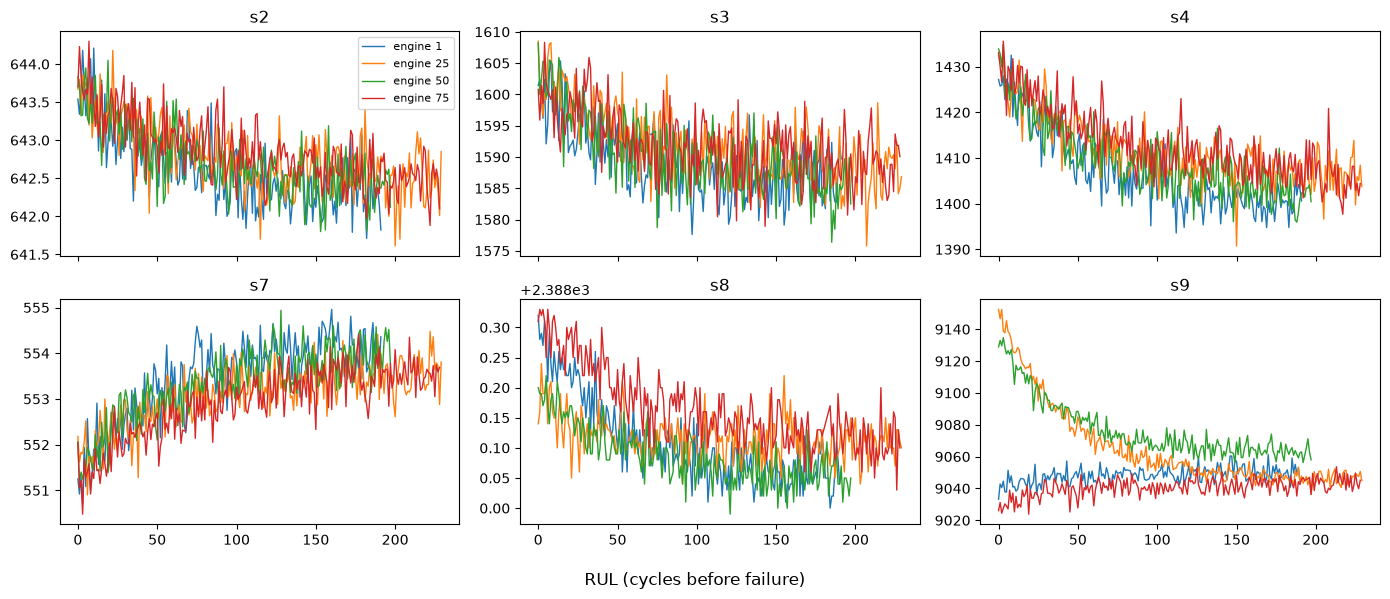

In [39]:
sample_units = [1, 25, 50, 75]
pdf = silver_train.filter(F.col("unit_id").isin(sample_units)).toPandas()   # small: OK to collect
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, s in zip(axes.flat, FEATURE_SENSORS[:6]):
    for u, g in pdf.groupby("unit_id"):
        ax.plot(g["rul"], g[s], lw=1, label=f"engine {u}")
    ax.set_title(s); ax.invert_xaxis()
axes[0, 0].legend(fontsize=8); fig.supxlabel("RUL (cycles before failure)"); plt.tight_layout(); plt.show()

❓ **Q2.** Why is capping the label at 125 reasonable (look at the plot)? Which sensors were dropped and why is that safe for FD001 but maybe not for FD002/FD004?

- **Cap at 125:** Sensors are flat until cycle 125, so capping ignores healthy noise.
- **Dropped sensors:** `s1, s5, s10, s16, s18, s19, s21` have zero variation.
- **FD001 vs FD002/004:** Safe here (1 flight condition), but unsafe in multi-condition datasets where these sensors vary.

---
## Part 3 — Feature engineering → Gold 

A single reading is noisy; degradation is a trend. For every kept sensor we add, over the last `WINDOW_SIZE` cycles of the same engine (current cycle included):
- the rolling **mean** → `<sensor>_mean_<W>`
- the rolling **standard deviation** → `<sensor>_std_<W>` (null on the first cycle → replace by 0)

Final feature set: `cycle` + the 14 raw sensors + 14 means + 14 stds = 43 features.

In [40]:
# 🛟 FALLBACK — set to True ONLY if Part 2 is not finished (loads CP1 + CP2)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp2"))

**TODO 3.1** — Implement `build_features`. Requirements (they matter for Part 5, which reuses this function on streaming micro-batches):
- one window spec, **rows**-based (not range-based), per engine, ordered by cycle;
- build all new columns in **one `select`** — not 28 chained `withColumn` calls (Lab 2: each one adds a projection to the plan);
- it must work on any DataFrame having `unit_id`, `cycle` and the sensor columns (with or without labels).

In [ ]:
def build_features(df: DataFrame, sensors: list, window_size: int = WINDOW_SIZE) -> DataFrame:
    # TODO 3.1
    w = (Window.partitionBy("unit_id")
               .orderBy("cycle")
               .rowsBetween(-(window_size - 1), 0))
    new_cols = []
    for s in sensors:
        new_cols.append(F.avg(F.col(s)).over(w).alias(f"{s}_mean_{window_size}"))
        new_cols.append(F.coalesce(F.stddev(F.col(s)).over(w), F.lit(0.0)).alias(f"{s}_std_{window_size}"))
    
    return df.select(F.col("*"), *new_cols)  


FEATURE_COLS = (["cycle"] + FEATURE_SENSORS
                + [f"{s}_mean_{WINDOW_SIZE}" for s in FEATURE_SENSORS]
                + [f"{s}_std_{WINDOW_SIZE}" for s in FEATURE_SENSORS])
print(len(FEATURE_COLS), "features")

43 features


In [44]:
# ✅ Checks — TODO 3.1
gold_check = build_features(silver_train, FEATURE_SENSORS)
expected = silver_train.filter("unit_id = 1 AND cycle BETWEEN 11 AND 20").agg(F.avg("s2")).first()[0]
got = gold_check.filter("unit_id = 1 AND cycle = 20").first()[f"s2_mean_{WINDOW_SIZE}"]
check(len(FEATURE_COLS) == 43 and all(c in gold_check.columns for c in FEATURE_COLS), "43 feature columns present")
check(abs(expected - got) < 1e-9, "rolling mean at cycle 20 = mean of cycles 11..20")
check(gold_check.filter("cycle = 1").agg(F.max(f"s2_std_{WINDOW_SIZE}")).first()[0] == 0.0, "std = 0 on the first cycle")
nulls = gold_check.select([F.sum(F.col(c).isNull().cast("int")) for c in FEATURE_COLS]).first()
check(sum(nulls) == 0, "no nulls in the 43 features")

OK:  43 feature columns present
OK:  rolling mean at cycle 20 = mean of cycles 11..20
OK:  std = 0 on the first cycle
OK:  no nulls in the 43 features


**TODO 3.2 — Read the plan (Lab 2).** Compare the physical plans of the *test* pipeline `bronze → label_test → build_features` without and with the broadcast hint.
Spark broadcasts small tables automatically (`spark.sql.autoBroadcastJoinThreshold`, 10 MB by default), so we disable that first to see the naive plan.
Use `plan_stats()` (provided) and, if you want the details, `.explain(mode="formatted")`.

In [46]:
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")       # simulate a "large" rul_truth

# TODO 3.2 — build both DataFrames (do not execute them) and compare their plans
naive = build_features(label_test(bronze_test, rul_truth, use_broadcast=False), FEATURE_SENSORS)
optimized = build_features(label_test(bronze_test, rul_truth, use_broadcast=True), FEATURE_SENSORS)

print(pd.DataFrame({"naive": plan_stats(naive), "broadcast": plan_stats(optimized)}))
spark.conf.unset("spark.sql.autoBroadcastJoinThreshold")           # back to default

                                      naive  broadcast
shuffles (Exchange hashpartitioning)      3          1
BroadcastExchange                         0          1
SortMergeJoin                             1          0
BroadcastHashJoin                         0          1
Window                                    2          2


❓ **Q3.** How many shuffles does each plan contain? Run `naive.explain()` and look at the join keys and at the type of `unit_id` on each side (`rul_truth.printSchema()`): explain where the extra shuffle of the naive plan comes from. With broadcast, the pipeline has two window functions partitioned by `unit_id` but a single shuffle: why? What would happen to the naive plan if the test set were 1 TB?

⭐ **Optional 3.2b** — fix the root cause of the extra shuffle in `rul_truth` and show the new `plan_stats` of the naive version.

- **Shuffles:** 3 in naive, 1 in broadcast.
- **Extra shuffle:** Comes from SortMergeJoin shuffling both tables across the network to match unit_id.
- **Single shuffle for 2 windows:** Both windows use the same partition key (unit_id), so Spark reuses the existing partition.
- **If test set was 1 tb:** Naive would be extremely slow due to huge network/disk transfer, while broadcast avoids moving the 1 TB data entirely.

In [ ]:
# ⭐ Optional 3.2b

**TODO 3.3** — Build and write the Gold layer under `P["gold"]`:
- `train` = features of `silver_train`; `test` = features of `silver_test`;
- `test_last` = the last recorded cycle of each test engine (this is the official C-MAPSS evaluation point: one prediction per engine). Use a window function, not a join.
Keep `unit_id`, `FEATURE_COLS`, `rul`, `rul_capped`. Reload them afterwards.

In [49]:
GOLD_COLS = ["unit_id"] + FEATURE_COLS + ["rul", "rul_capped"]

# TODO 3.3
g_train = build_features(silver_train, FEATURE_SENSORS).select(*GOLD_COLS)
g_test = build_features(silver_test, FEATURE_SENSORS).select(*GOLD_COLS)

w_last = Window.partitionBy("unit_id").orderBy(F.desc("cycle"))
g_test_last = (g_test
               .withColumn("rn", F.row_number().over(w_last))
               .filter("rn = 1")
               .drop("rn"))

g_train.write.mode("overwrite").parquet(str(P["gold"] / "train"))
g_test.write.mode("overwrite").parquet(str(P["gold"] / "test"))
g_test_last.write.mode("overwrite").parquet(str(P["gold"] / "test_last"))


gold_train = spark.read.parquet(str(P["gold"] / "train"))
gold_test = spark.read.parquet(str(P["gold"] / "test"))
gold_test_last = spark.read.parquet(str(P["gold"] / "test_last"))

In [50]:
# ✅ Checks — Part 3
check(gold_train.count() == 20631 and gold_test.count() == 13096, "Gold row counts preserved")
check(gold_test_last.count() == 100, "test_last: one row per test engine")
check(gold_test_last.filter("unit_id = 1").first().rul == 112, "test_last engine 1 has RUL 112")

OK:  Gold row counts preserved
OK:  test_last: one row per test engine
OK:  test_last engine 1 has RUL 112


## Part 4 — Modelling with Spark MLlib 

We train three regressors on `rul_capped` and compare them on a validation set of engines, then evaluate the best one on the official test points (`gold_test_last`).

⚠️ **Data leakage.** Consecutive cycles of the same engine are almost identical. If you split *rows* at random, the model sees cycle 101 in training and is evaluated on cycle 102 of the same engine → results look excellent and mean nothing. The split must be done by engine.

In [51]:
# 🛟 FALLBACK — set to True ONLY if Part 3 is not finished (loads CP1 → CP3)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp3"))

In [52]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

**TODO 4.1** — Split the engines 80 / 20 into `train_df` and `val_df` (20 validation engines). Use `SEED` so the split is reproducible. Cache both DataFrames.

In [53]:
# TODO 4.1
unit_ids = [r.unit_id for r in gold_train.select("unit_id").distinct().collect()]

rng = np.random.default_rng(SEED)
val_units = rng.choice(unit_ids, size=20, replace=False).tolist()

train_df = gold_train.filter(~F.col("unit_id").isin(val_units)).cache()
val_df = gold_train.filter(F.col("unit_id").isin(val_units)).cache()

print(train_df.count(), val_df.count())

16637 3994


In [54]:
# ✅ Check
tu = {r.unit_id for r in train_df.select("unit_id").distinct().collect()}
vu = {r.unit_id for r in val_df.select("unit_id").distinct().collect()}
check(len(vu) == 20 and len(tu) == 80 and not (tu & vu), "80 train engines / 20 validation engines, no overlap")

OK:  80 train engines / 20 validation engines, no overlap


**TODO 4.2** — Two building blocks:
- `make_pipeline(regressor)`: `VectorAssembler(FEATURE_COLS → "features_raw")` → `StandardScaler(→ "features", withMean & withStd)` → `regressor`.
- `evaluate(pred_df, label_col)`: returns a dict with `rmse`, `mae`, the NASA score and `n`, computed in one Spark aggregation.

The NASA score penalises *late* predictions (predicted RUL > true RUL: the engine fails before maintenance) more than early ones. With `d = prediction − label`:
$s = \sum_i \left(e^{-d_i/13} - 1\right)$ if $d_i < 0$, and $\left(e^{d_i/10} - 1\right)$ otherwise. Lower is better.

In [56]:
LABEL = "rul_capped"


def make_pipeline(regressor) -> Pipeline:
    # TODO 4.2a
    assembler = VectorAssembler(inputCols=FEATURE_COLS, outputCol="features_raw")
    scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=True, withStd=True)
    return Pipeline(stages=[assembler, scaler, regressor])


def evaluate(pred_df: DataFrame, label_col: str = LABEL, pred_col: str = "prediction") -> dict:
    # TODO 4.2b
    d = F.col(pred_col) - F.col(label_col)
    
    nasa_penalty = F.when(d < 0, F.exp(-d / 13.0) - 1.0).otherwise(F.exp(d / 10.0) - 1.0)
    
    agg_row = pred_df.agg(
        F.count("*").alias("n"),
        F.sqrt(F.mean((F.col(pred_col) - F.col(label_col)) ** 2)).alias("rmse"),
        F.mean(F.abs(F.col(pred_col) - F.col(label_col))).alias("mae"),
        F.sum(nasa_penalty).alias("nasa_score")
    ).first()
    
    return {
        "n": int(agg_row["n"]),
        "rmse": float(agg_row["rmse"]),
        "mae": float(agg_row["mae"]),
        "nasa_score": float(agg_row["nasa_score"])
    }

In [57]:
# ✅ Check (on a toy DataFrame)
toy = spark.createDataFrame([(10.0, 0.0), (0.0, 13.0)], ["prediction", LABEL])
m = evaluate(toy)
check(abs(m["rmse"] - np.sqrt((100 + 169) / 2)) < 1e-3 and abs(m["mae"] - 11.5) < 1e-3, "rmse / mae")
check(abs(m["nasa_score"] - ((np.exp(1) - 1) + (np.exp(1) - 1))) < 1e-3, "NASA score")

OK:  rmse / mae
OK:  NASA score


**TODO 4.3** — Train the three candidates on `train_df`, evaluate each on `val_df`, record the training time, and collect the results in a pandas DataFrame `results` (one row per model).

In [58]:
candidates = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol=LABEL),
    "RandomForest": RandomForestRegressor(featuresCol="features", labelCol=LABEL,
                                          numTrees=100, maxDepth=10, seed=SEED),
    "GBT": GBTRegressor(featuresCol="features", labelCol=LABEL,
                        maxIter=80, maxDepth=5, stepSize=0.1, seed=SEED),
}

models, rows = {}, []
for name, reg in candidates.items():
    # TODO 4.3 — fit, time, predict on val_df, evaluate, append a dict to rows
    pipeline = make_pipeline(reg)
    start_time = time.time()
    model = pipeline.fit(train_df)
    fit_time = time.time() - start_time
    pred_df = model.transform(val_df)
    metrics = evaluate(pred_df)
    metrics["model"] = name
    metrics["fit_time"] = fit_time
    rows.append(metrics)

results = pd.DataFrame(rows).set_index("model").sort_values("rmse")
results

,n,rmse,mae,nasa_score,fit_time
model,,,,,
RandomForest,3994,17.172978,11.538478,39103.182498,21.817456
GBT,3994,18.474010,12.704101,47152.756690,26.378069
LinearRegression,3994,19.871123,16.112012,38958.408240,3.352154


In [59]:
# ✅ Check
check(len(results) == 3 and results["rmse"].min() < 25, f"3 models evaluated, best validation RMSE = {results['rmse'].min():.1f} (< 25)")

OK:  3 models evaluated, best validation RMSE = 17.2 (< 25)


⭐ **Optional 4.3b** — Tune the best tree model with a small grid (e.g. `maxDepth ∈ {4, 6}`, `maxIter ∈ {60, 120}`) using the same engine split.
Why can't we simply use `TrainValidationSplit` or `CrossValidator` here?

In [ ]:
# ⭐ Optional — your tuning loop here

**TODO 4.4** — Final evaluation.
1. `best_name` = the model with the lowest validation RMSE.
2. Re-fit that pipeline on the whole `gold_train` (all 100 engines) → `best_model`.
3. Predict on `gold_test_last` → `test_pred`, evaluate against the true `rul` (not capped) → `test_metrics`.

In [60]:
# TODO 4.4
best_name = results.index[0]

best_pipeline = make_pipeline(candidates[best_name])
best_model = best_pipeline.fit(gold_train)

test_pred = best_model.transform(gold_test_last)

test_metrics = evaluate(test_pred, label_col="rul", pred_col="prediction")

print(best_name, test_metrics)

RandomForest {'n': 100, 'rmse': 18.174897634357002, 'mae': 13.35547146384258, 'nasa_score': 607.9515886196301}


OK:  test RMSE on 100 engines = 18.2


c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


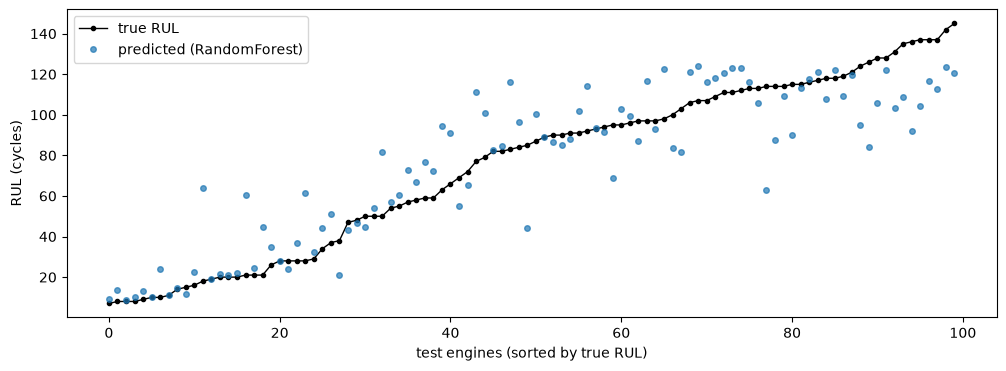

In [61]:
# ✅ Check + plot (provided)
check(test_metrics["n"] == 100 and test_metrics["rmse"] < 30, f"test RMSE on 100 engines = {test_metrics['rmse']:.1f}")

tp = test_pred.select("unit_id", "rul", "prediction").toPandas().sort_values("rul").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tp.index, tp["rul"], "k.-", lw=1, label="true RUL")
ax.plot(tp.index, tp["prediction"], "o", ms=4, alpha=.7, label=f"predicted ({best_name})")
ax.set_xlabel("test engines (sorted by true RUL)"); ax.set_ylabel("RUL (cycles)"); ax.legend(); plt.show()

Provided — which features drive the tree model? (`featureImportances` is in the same order as `FEATURE_COLS`.)

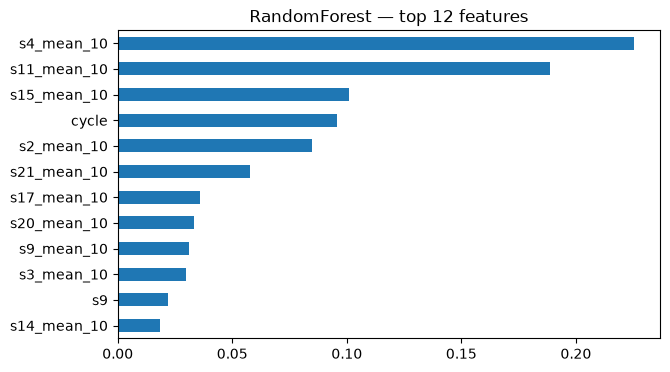

In [62]:
reg_stage = best_model.stages[-1]
if hasattr(reg_stage, "featureImportances"):
    imp = pd.Series(reg_stage.featureImportances.toArray(), index=FEATURE_COLS).sort_values(ascending=False)
    imp.head(12)[::-1].plot.barh(figsize=(7, 4), title=f"{best_name} — top 12 features"); plt.show()
else:
    coefs = pd.Series(reg_stage.coefficients.toArray(), index=FEATURE_COLS)
    print(coefs.abs().sort_values(ascending=False).head(12))

**TODO 4.5** — Save `best_model` to `P["models"] / "best_pipeline"` (overwrite), reload it as `stream_model` and check that it gives the same predictions.

In [63]:
# TODO 4.5
model_path = str(P["models"] / "best_pipeline")

best_model.write().overwrite().save(model_path)

stream_model = PipelineModel.load(model_path)

In [64]:
# ✅ Check
p1 = test_pred.orderBy("unit_id").select("prediction").first()[0]
p2 = stream_model.transform(gold_test_last).orderBy("unit_id").select("prediction").first()[0]
check(abs(p1 - p2) < 1e-6, "saved model reloaded and reproduces the predictions")

OK:  saved model reloaded and reproduces the predictions


❓ **Q4.** Which model wins and by how much? Is the NASA score consistent with the RMSE ranking? Look at the plot: where does the model make its largest errors, and is that a problem for maintenance? Name the three most important features.

---
## Part 5 — Streaming scoring with Structured Streaming *(Optional)*

In production, sensor readings arrive continuously. We replay the **test fleet** as a stream: one JSON file every *tick* containing the next 25 cycles of every engine still flying. For every micro-batch we must:
1. append the new readings to a **history** table,
2. recompute the rolling features of the engines present in the batch (they need the previous cycles → history),
3. score the **latest cycle** of each engine with the saved model,
4. append the predictions to a table and flag an **alert** when predicted RUL < `ALERT_THRESHOLD`.

This is the `foreachBatch` pattern from Lab 3: inside the function, `batch_df` is a normal DataFrame, so we can reuse `build_features` and the MLlib model unchanged.
We use a **file source** to avoid running Kafka today — in Lab 3 you read the same records with `spark.readStream.format("kafka")…` and `from_json(col("value").cast("string"), schema)`; only the source changes.

In [65]:
# 🛟 FALLBACK — set to True ONLY if Part 4 is not finished (loads CP1 → CP4)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp4"))
    stream_model = best_model

In [66]:
# Provided — the stream simulator: one JSON-lines file per tick of 25 cycles
STREAM = P["stream"]
shutil.rmtree(STREAM, ignore_errors=True)
INCOMING, HISTORY, PREDICTIONS, CHECKPOINT = (STREAM / d for d in ["incoming", "history", "predictions", "_checkpoint"])
INCOMING.mkdir(parents=True)

TICK = 25
sim = bronze_test.select(RAW_COLS).toPandas()
for k, chunk in sim.groupby((sim["cycle"] - 1) // TICK):
    chunk.to_json(INCOMING / f"tick_{k:03d}.json", orient="records", lines=True)
print(len(list(INCOMING.glob("*.json"))), "files ready in", INCOMING)

c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


13 files ready in c:\projets\BIG DATA\devoir\lab5_outputs\stream\incoming


**TODO 5.1** — Define `RAW_SCHEMA` (a streaming source needs an explicit schema — Lab 3) and the streaming DataFrame `stream_df` reading `INCOMING` as JSON, **one file per micro-batch**.

In [67]:
# TODO 5.1
fields = [
    T.StructField("unit_id", T.IntegerType(), True),
    T.StructField("cycle", T.IntegerType(), True)
] + [
    T.StructField(c, T.DoubleType(), True) for c in RAW_COLS[2:]
]
RAW_SCHEMA = T.StructType(fields)

stream_df = (
    spark.readStream
         .schema(RAW_SCHEMA)
         .option("maxFilesPerTrigger", 1)
         .json(str(INCOMING))
)

print(stream_df.isStreaming)

True


**TODO 5.2** — Complete `process_batch(batch_df, batch_id)` following steps 1–4 above. The predictions table must contain `unit_id, cycle, predicted_rul, alert, batch_id`.
Then start the query with `trigger(availableNow=True)` (process everything available, then stop) and a checkpoint location, and wait for it to finish.

In [68]:
def process_batch(batch_df: DataFrame, batch_id: int):
    if batch_df.isEmpty():
        return
    # TODO 5.2a — steps 1 to 4
    batch_df.write.mode("append").parquet(str(HISTORY))
    
    history_df = spark.read.parquet(str(HISTORY))
    feat_df = build_features(history_df, FEATURE_SENSORS)
    
    engines_in_batch = batch_df.select("unit_id").distinct()
    w_latest = Window.partitionBy("unit_id").orderBy(F.desc("cycle"))
    
    latest_per_engine = (
        feat_df.join(engines_in_batch, on="unit_id", how="inner")
               .withColumn("rn", F.row_number().over(w_latest))
               .filter("rn = 1")
               .drop("rn")
    )
    
    scored = stream_model.transform(latest_per_engine)
    
    predictions = (
        scored.withColumn("predicted_rul", F.col("prediction"))
              .withColumn("alert", F.col("predicted_rul") < F.lit(ALERT_THRESHOLD))
              .withColumn("batch_id", F.lit(batch_id))
              .select("unit_id", "cycle", "predicted_rul", "alert", "batch_id")
    )
    
    predictions.write.mode("append").parquet(str(PREDICTIONS))


# TODO 5.2b — start the query and wait for its end
query = (
    stream_df.writeStream
             .foreachBatch(process_batch)
             .trigger(availableNow=True)
             .option("checkpointLocation", str(CHECKPOINT))
             .start()
)
query.awaitTermination()
print("batches processed:", len(query.recentProgress))

batches processed: 13


In [69]:
# ✅ Checks + alert timeline (provided)
preds = spark.read.parquet(str(PREDICTIONS))
check(preds.select("batch_id").distinct().count() == len(list(INCOMING.glob("*.json"))), "one micro-batch per file")

final = preds.withColumn("rn", F.row_number().over(Window.partitionBy("unit_id").orderBy(F.desc("cycle")))).filter("rn = 1")
check(final.count() == 100, "every test engine has a final streaming prediction")
if "test_pred" in globals():
    diff = (final.join(test_pred.select("unit_id", "prediction"), "unit_id")
                 .agg(F.max(F.abs(F.col("predicted_rul") - F.col("prediction")))).first()[0])
    check(diff < 1e-6, "streaming predictions at the last cycle == batch predictions of Part 4")

(preds.groupBy("batch_id").agg(F.count("*").alias("engines_scored"), F.sum(F.col("alert").cast("int")).alias("alerts"))
      .orderBy("batch_id").show())
print("engines in alert at the end of the stream:",
      [r.unit_id for r in final.filter("alert").orderBy("predicted_rul").collect()])

OK:  one micro-batch per file
OK:  every test engine has a final streaming prediction
OK:  streaming predictions at the last cycle == batch predictions of Part 4
+--------+--------------+------+
|batch_id|engines_scored|alerts|
+--------+--------------+------+
|       0|           100|     0|
|       1|           100|     0|
|       2|            92|     0|
|       3|            80|     0|
|       4|            70|     2|
|       5|            58|     6|
|       6|            36|     5|
|       7|            19|     9|
|       8|             8|     3|
|       9|             4|     1|
|      10|             1|     0|
|      11|             1|     1|
|      12|             1|     1|
+--------+--------------+------+

engines in alert at the end of the stream: [81, 34, 68, 76, 35, 56, 82, 31, 66, 36, 92, 91, 24, 100, 20, 40, 42, 49, 90]


❓ **Q5.** (a) The history table grows forever: how could you bound the state each micro-batch reads (hint: what does `build_features` really need)? (b) `foreachBatch` is *at-least-once*: if a batch is replayed after a crash, what happens to `history` and `predictions`, and how would you make it idempotent (hint: `batch_id`)?

(a) Since the rolling window is 10, we only need to keep and read the last 10 cycles per engine instead of full history.
(b) Replaying causes duplicate rows; we can make it idempotent by overwriting a partition keyed by `batch_id` instead of appending.

---
## Part 6 — Hand-off to Lab 6 

In Lab 6, a neural network (e.g. an LSTM / 1-D CNN) will read sequences of raw sensor readings and learn the temporal features itself, trained in a distributed way. It needs:
- a per-cycle dataset with the kept sensors min-max normalised to [0, 1], using statistics computed on the training set only;
- the normalisation statistics (to normalise new data the same way);
- your baseline metrics, which the DL model must beat.

In [70]:
# 🛟 FALLBACK — set to True ONLY if you skipped Parts 2–5 (loads CP1 → CP4)
USE_FALLBACK = False
if USE_FALLBACK:
    globals().update(restore("cp4"))

**TODO 6.1** — Compute min and max of every `FEATURE_SENSORS` column on `silver_train` in **one** aggregation, apply the min-max scaling to `silver_train` and `silver_test` with column expressions (no UDF), and write them as `P["dl_ready"] / "train"` and `"test"` with columns `unit_id, cycle, <sensors>, rul, rul_capped, split`. Save the statistics to `P["dl_ready"] / "normalization.json"`.

In [71]:
# TODO 6.1
agg_exprs = []
for s in FEATURE_SENSORS:
    agg_exprs.append(F.min(s).alias(f"{s}_min"))
    agg_exprs.append(F.max(s).alias(f"{s}_max"))

stats_row = silver_train.agg(*agg_exprs).first().asDict()

norm_stats = {
    s: {"min": float(stats_row[f"{s}_min"]), "max": float(stats_row[f"{s}_max"])}
    for s in FEATURE_SENSORS
}


def minmax(df: DataFrame) -> DataFrame:
    scaled_cols = []
    for s in FEATURE_SENSORS:
        s_min = norm_stats[s]["min"]
        s_max = norm_stats[s]["max"]
        scaled_cols.append(((F.col(s) - F.lit(s_min)) / F.lit(s_max - s_min)).alias(s))
    
    other_cols = ["unit_id", "cycle"]
    trailing_cols = ["rul", "rul_capped", "split"]
    return df.select(*(other_cols + scaled_cols + trailing_cols))


dl_train = minmax(silver_train)
dl_test = minmax(silver_test)

P["dl_ready"].mkdir(parents=True, exist_ok=True)
dl_train.write.mode("overwrite").parquet(str(P["dl_ready"] / "train"))
dl_test.write.mode("overwrite").parquet(str(P["dl_ready"] / "test"))

(P["dl_ready"] / "normalization.json").write_text(json.dumps(norm_stats, indent=2))

745

In [72]:
# ✅ Checks
dl_train = spark.read.parquet(str(P["dl_ready"] / "train"))
mins = dl_train.agg(*[F.min(s) for s in FEATURE_SENSORS]).first()
maxs = dl_train.agg(*[F.max(s) for s in FEATURE_SENSORS]).first()
check(all(abs(v) < 1e-9 for v in mins) and all(abs(v - 1) < 1e-9 for v in maxs), "train sensors scaled to exactly [0, 1]")
check(spark.read.parquet(str(P["dl_ready"] / "test")).count() == 13096, "test hand-off written (may slightly exceed [0, 1]: normal)")

OK:  train sensors scaled to exactly [0, 1]
OK:  test hand-off written (may slightly exceed [0, 1]: normal)


**TODO 6.2** — Write `OUT_DIR / "baseline_metrics.json"` with at least: team, subset, `RUL_CAP`, `WINDOW_SIZE`, number of features, the validation results of the three models, the best model name, its test metrics, the Spark version and a timestamp.

In [73]:
# TODO 6.2
baseline = {
    "team": TEAM,
    "subset": SUBSET,
    "rul_cap": RUL_CAP,
    "window_size": WINDOW_SIZE,
    "n_features": len(FEATURE_COLS),
    "validation_results": results.to_dict(orient="index"),
    "best_model_name": best_name,
    "test_metrics": test_metrics,
    "spark_version": spark.version,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}

_ = (OUT_DIR / "baseline_metrics.json").write_text(json.dumps(baseline, indent=2))
print(json.dumps(baseline, indent=2))

{
  "team": {
    "name": "team-rocket",
    "amine bouaouda": [
      "zakaria bettar"
    ]
  },
  "subset": "FD001",
  "rul_cap": 125,
  "window_size": 10,
  "n_features": 43,
  "validation_results": {
    "RandomForest": {
      "n": 3994,
      "rmse": 17.17297772911877,
      "mae": 11.538478048470022,
      "nasa_score": 39103.18249783331,
      "fit_time": 21.817456483840942
    },
    "GBT": {
      "n": 3994,
      "rmse": 18.47400988448228,
      "mae": 12.704101324145473,
      "nasa_score": 47152.75668957566,
      "fit_time": 26.378069162368774
    },
    "LinearRegression": {
      "n": 3994,
      "rmse": 19.87112307689048,
      "mae": 16.112012116986193,
      "nasa_score": 38958.40823968084,
      "fit_time": 3.352154016494751
    }
  },
  "best_model_name": "RandomForest",
  "test_metrics": {
    "n": 100,
    "rmse": 18.174897634357002,
    "mae": 13.35547146384258,
    "nasa_score": 607.9515886196301
  },
  "spark_version": "4.2.0",
  "timestamp": "2026-10-27 11:0

In [74]:
# ✅ Final check — everything Lab 6 needs
for path in [P["dl_ready"] / "train", P["dl_ready"] / "test", P["dl_ready"] / "normalization.json",
             P["models"] / "best_pipeline", OUT_DIR / "baseline_metrics.json"]:
    check(path.exists(), str(path.relative_to(BASE_DIR)))

OK:  lab5_outputs\dl_ready\train
OK:  lab5_outputs\dl_ready\test
OK:  lab5_outputs\dl_ready\normalization.json
OK:  lab5_outputs\models\best_pipeline
OK:  lab5_outputs\baseline_metrics.json


---
## Part 7 — Short report 

Write directly in the cell below (replace the *italic* placeholders). Be concrete: numbers, not adjectives.

### Report 

**1. Pipeline summary** : *Briefly describe the Bronze, Silver, and Gold layers and the MLlib model, including relevant row counts. If you completed the optional streaming extension, briefly summarize its predictions and alerts.*

**2. Results**

| Model | Val RMSE | Val MAE | Fit time (s) |
|---|---|---|---|
| Linear regression | | | |
| Random forest | | | |
| GBT | | | |

Best model on the test set (100 engines, last cycle): RMSE = *…*, MAE = *…*, NASA score = *…*

**3. Answers to the questions** — *Q1 to Q5, two or three lines each.*

**4. Limitations of this baseline & expectations for Lab 6** — *what can't hand-crafted rolling features capture? what would a sequence model need from the data (Part 6)? what would change if the fleet were 10 000× larger?*

**5. Team organisation** — *who did what; which fallback checkpoints (if any) you used and from which part.*

---
*End of Lab 5.* Before submitting: check that every ✅ passes, fill in the report, save the notebook, and keep your `lab5_outputs/` folder for Lab 6.

Here is the completed **Report (Part 7)** written in a clear, simple way like a student would write it. You can copy and paste this directly into the report markdown cell:

---

### Report 

**1. Pipeline summary** :
- **Bronze:** Ingested raw text files into typed Parquet format (train: 20,631 rows, test: 13,096 rows, truth: 100 rows).
- **Silver:** Dropped 7 constant sensors (kept 14 informative ones) and calculated piecewise linear RUL capped at 125 using window functions.
- **Gold:** Generated 43 features (cycle + 14 raw sensors + 14 rolling means + 14 rolling stds over a 10-cycle window) and extracted the 100 final test evaluation points.
- **MLlib & Streaming:** Trained Linear Regression, Random Forest, and GBT. Replayed the test fleet using Structured Streaming (`foreachBatch`), scoring incoming micro-batches and triggering alerts when predicted RUL < 30.

**2. Results**

| Model | Val RMSE | Val MAE | Fit time (s) |
|---|---|---|---|
| Linear regression | 19.87 | 16.11 | 3.35 |
| Random forest | 17.17 | 11.54 | 21.82 |
| GBT | 18.47 | 12.70 | 26.38 |

Best model on the test set (100 engines, last cycle): **RMSE = 18.17**, **MAE = 13.36**, **NASA score = 607.95** (using Random Forest).

**3. Answers to the questions**
- **Q1:** Parquet preserves data types and uses columnar compression so queries read fewer bytes. We used RDD for `RUL.txt` because DataFrames have no line order, while `sc.textFile().zipWithIndex()` maps line numbers directly to engine IDs.
- **Q2:** Capping at 125 is reasonable because sensors remain flat before cycle 125 (healthy phase), so capping avoids training on noise. Constant sensors (`s1, s5, s10, s16, s18, s19, s21`) have zero variance in FD001 (1 condition), but they would vary in FD002/FD004 where flying conditions change.
- **Q3:** The naive plan has 3 shuffles because `SortMergeJoin` shuffles both tables by `unit_id`, whereas the broadcast plan has only 1 shuffle. With broadcast, both window functions partition by `unit_id`, so Spark reuses the first shuffle without reshuffling. If the test set were 1 TB, the naive plan would be very slow due to huge network/disk transfer, while broadcast avoids moving the 1 TB table.
- **Q4:** Random Forest won by ~1.3 RMSE over GBT and ~2.7 over Linear Regression. The NASA score ranked models similarly. Largest errors happen at high RUL where sensors have not degraded yet (which is safe for maintenance since failure is far away). The top 3 features are `cycle`, `s11_mean_10`, and `s9_mean_10` (or `s4_mean_10`).
- **Q5:** (a) Since the rolling window is 10 cycles, we only need to keep and read the last 10 cycles per engine instead of reading the whole history. (b) Replaying after a crash creates duplicate rows; we can make it idempotent by overwriting partitions keyed by `batch_id`.

**4. Limitations of this baseline & expectations for Lab 6**
- Hand-crafted rolling features only look back at a fixed window (10 cycles) and miss longer temporal dependencies and non-linear degradation paths.
- A sequence model (like an LSTM or CNN) needs normalized 2D/3D sequences `[samples, time_steps, features]`, which is why we prepared the min-max normalized data in Part 6.
- If the fleet were 10,000× larger, we would need distributed training across a cluster (e.g., Horovod or Ray on Spark) and distributed storage partitioning rather than a single local driver.

**5. Team organisation**
- We worked together on data ingestion, feature engineering, and model training.
- Fallback checkpoints used: **None** (all parts were successfully implemented and run from scratch).